In [1]:
# Classification of Fashion MNIST Dataset (TensorFlow/Keras) 


In [2]:
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Num GPUs Available:", len(tf.config.list_physical_devices("GPU")))


TensorFlow: 2.21.0
Num GPUs Available: 0


In [3]:
(x_train_raw, y_train), (x_test_raw, y_test) = tf.keras.datasets.fashion_mnist.load_data()

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot",
]

print("Training images:", x_train_raw.shape)
print("Training labels:", y_train.shape)
print("Test images:", x_test_raw.shape)
print("Pixel range:", int(x_train_raw.min()), "to", int(x_train_raw.max()))
print("Number of classes:", len(class_names))


Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Pixel range: 0 to 255
Number of classes: 10


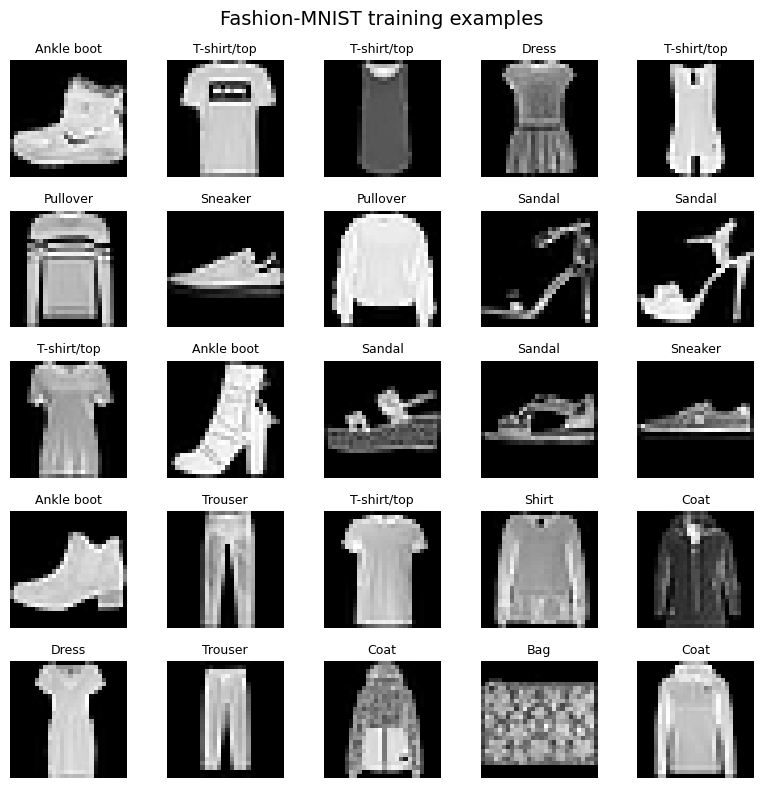

In [4]:
fig, axes = plt.subplots(5, 5, figsize=(8, 8))
for ax, image, label in zip(axes.flat, x_train_raw[:25], y_train[:25]):
    ax.imshow(image, cmap="gray")
    ax.set_title(class_names[int(label)], fontsize=9)
    ax.axis("off")
fig.suptitle("Fashion-MNIST training examples", fontsize=14)
plt.tight_layout()
plt.show()


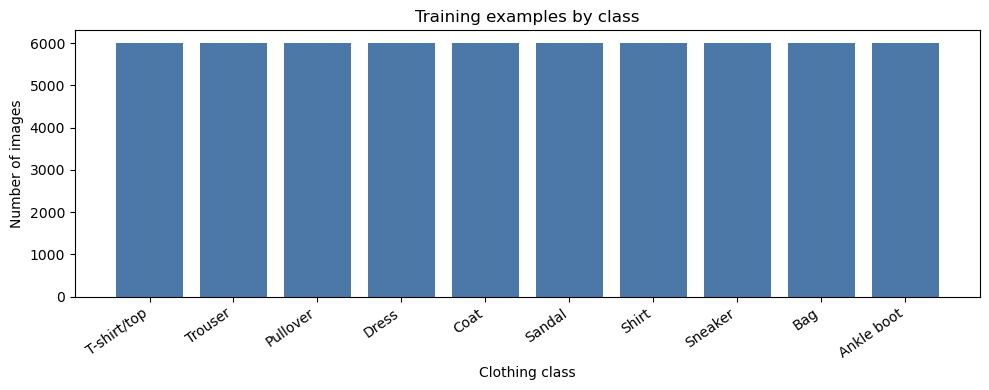

Class counts: {'T-shirt/top': 6000, 'Trouser': 6000, 'Pullover': 6000, 'Dress': 6000, 'Coat': 6000, 'Sandal': 6000, 'Shirt': 6000, 'Sneaker': 6000, 'Bag': 6000, 'Ankle boot': 6000}


In [5]:
train_class_counts = np.bincount(y_train, minlength=len(class_names))

plt.figure(figsize=(10, 4))
plt.bar(class_names, train_class_counts, color="#4C78A8")
plt.title("Training examples by class")
plt.xlabel("Clothing class")
plt.ylabel("Number of images")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

print("Class counts:", dict(zip(class_names, train_class_counts.tolist())))


In [6]:
x_train = x_train_raw.astype("float32") / 255.0
x_test = x_test_raw.astype("float32") / 255.0

# Shuffle only the training set before validation_split is applied.
shuffle_rng = np.random.default_rng(SEED)
train_order = shuffle_rng.permutation(len(y_train))
x_train = x_train[train_order]
y_train_shuffled = y_train[train_order]

x_train_cnn = x_train[..., np.newaxis]
x_test_cnn = x_test[..., np.newaxis]

print("MLP input shape:", x_train.shape[1:])
print("CNN input shape:", x_train_cnn.shape[1:])
print("Normalized pixel range:", float(x_train.min()), "to", float(x_train.max()))


MLP input shape: (28, 28)
CNN input shape: (28, 28, 1)
Normalized pixel range: 0.0 to 1.0


In [7]:
mlp_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dropout(0.30),
    tf.keras.layers.Dense(10, activation="softmax"),
], name="fashion_mnist_mlp")

mlp_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

mlp_model.summary()


Model: "fashion_mnist_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │         200,960 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           2,570 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 203,530 (795.04 KB)

 Trainable params: 203,530 (795.04 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
mlp_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
)

start_time = time.time()
mlp_history = mlp_model.fit(
    x_train,
    y_train_shuffled,
    epochs=12,
    batch_size=128,
    validation_split=0.10,
    callbacks=[mlp_early_stopping],
    verbose=1,
)
mlp_training_seconds = time.time() - start_time

print(f"MLP training time: {mlp_training_seconds:.1f} seconds")


Epoch 1/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 13s 22ms/step - accuracy: 0.7920 - loss: 0.5916 - val_accuracy: 0.8400 - val_loss: 0.4397
Epoch 2/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.8507 - loss: 0.4193 - val_accuracy: 0.8650 - val_loss: 0.3810
Epoch 3/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 13s 32ms/step - accuracy: 0.8616 - loss: 0.3811 - val_accuracy: 0.8682 - val_loss: 0.3565
Epoch 4/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 18s 26ms/step - accuracy: 0.8701 - loss: 0.3583 - val_accuracy: 0.8787 - val_loss: 0.3363
Epoch 5/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 21s 27ms/step - accuracy: 0.8764 - loss: 0.3396 - val_accuracy: 0.8803 - val_loss: 0.3254
Epoch 6/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 20s 24ms/step - accuracy: 0.8811 - loss: 0.3264 - val_accuracy: 0.8808 - val_loss: 0.3212
Epoch 7/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 10s 24ms/step - accuracy: 0.8841 - loss: 0.3151 - val_accuracy: 0.8852 - val_loss: 0.3178
Epoch 8/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 19s 21ms/step - accuracy: 0.8887 - loss: 0.3044 - va

In [9]:
# build and train cnn
cnn_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(32, kernel_size=3, padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D(pool_size=2),
    tf.keras.layers.Conv2D(64, kernel_size=3, padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D(pool_size=2),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.30),
    tf.keras.layers.Dense(10, activation="softmax"),
], name="fashion_mnist_cnn")

cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

cnn_model.summary()


Model: "fashion_mnist_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 28, 28, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 14, 14, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 14, 14, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 7, 7, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 3136)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │         401,536 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
cnn_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
)

start_time = time.time()
cnn_history = cnn_model.fit(
    x_train_cnn,
    y_train_shuffled,
    epochs=12,
    batch_size=128,
    validation_split=0.10,
    callbacks=[cnn_early_stopping],
    verbose=1,
)
cnn_training_seconds = time.time() - start_time

print(f"CNN training time: {cnn_training_seconds:.1f} seconds")


Epoch 1/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 65s 142ms/step - accuracy: 0.8013 - loss: 0.5542 - val_accuracy: 0.8707 - val_loss: 0.3466
Epoch 2/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 82s 142ms/step - accuracy: 0.8754 - loss: 0.3496 - val_accuracy: 0.8957 - val_loss: 0.2863
Epoch 3/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 83s 145ms/step - accuracy: 0.8914 - loss: 0.2991 - val_accuracy: 0.9050 - val_loss: 0.2565
Epoch 4/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 71s 119ms/step - accuracy: 0.9027 - loss: 0.2696 - val_accuracy: 0.9092 - val_loss: 0.2359
Epoch 5/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 87s 131ms/step - accuracy: 0.9104 - loss: 0.2431 - val_accuracy: 0.9113 - val_loss: 0.2349
Epoch 6/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 83s 133ms/step - accuracy: 0.9178 - loss: 0.2257 - val_accuracy: 0.9123 - val_loss: 0.2271
Epoch 7/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 82s 134ms/step - accuracy: 0.9241 - loss: 0.2067 - val_accuracy: 0.9183 - val_loss: 0.2152
Epoch 8/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 56s 133ms/step - accuracy: 0.9284 - loss: 0

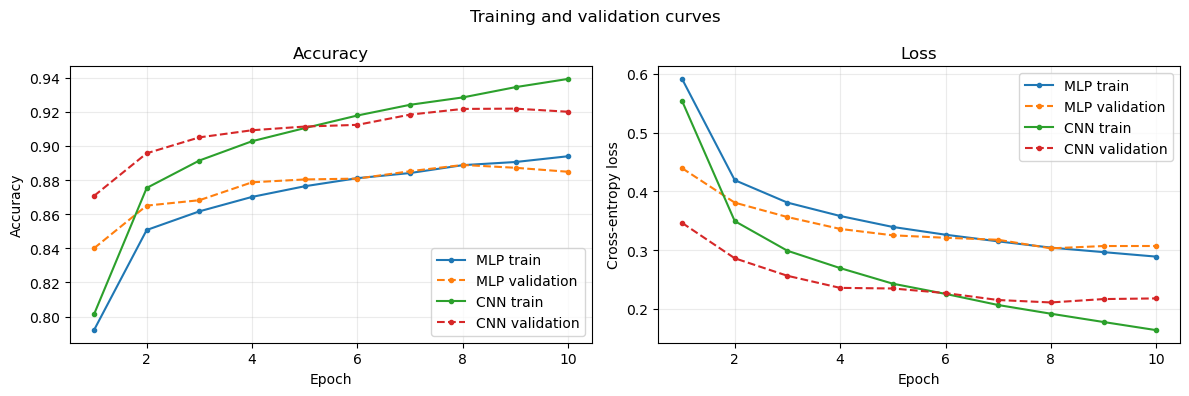

In [11]:
# Compare training curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for name, history in [("MLP", mlp_history), ("CNN", cnn_history)]:
    epochs_ran = range(1, len(history.history["accuracy"]) + 1)
    axes[0].plot(epochs_ran, history.history["accuracy"], marker=".", label=f"{name} train")
    axes[0].plot(epochs_ran, history.history["val_accuracy"], marker=".", linestyle="--", label=f"{name} validation")
    axes[1].plot(epochs_ran, history.history["loss"], marker=".", label=f"{name} train")
    axes[1].plot(epochs_ran, history.history["val_loss"], marker=".", linestyle="--", label=f"{name} validation")

axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Cross-entropy loss")

for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend()

fig.suptitle("Training and validation curves")
plt.tight_layout()
plt.show()


In [12]:
mlp_test_results = mlp_model.evaluate(x_test, y_test, verbose=0, return_dict=True)
cnn_test_results = cnn_model.evaluate(x_test_cnn, y_test, verbose=0, return_dict=True)

print(f"{'Model':<10} {'Test loss':>12} {'Test accuracy':>16} {'Train seconds':>16}")
print("-" * 58)
print(f"{'MLP':<10} {mlp_test_results['loss']:>12.4f} {mlp_test_results['accuracy']:>15.2%} {mlp_training_seconds:>15.1f}")
print(f"{'CNN':<10} {cnn_test_results['loss']:>12.4f} {cnn_test_results['accuracy']:>15.2%} {cnn_training_seconds:>15.1f}")

accuracy_difference = cnn_test_results["accuracy"] - mlp_test_results["accuracy"]
print()
print(f"CNN minus MLP test accuracy: {accuracy_difference:+.2%}")


Model         Test loss    Test accuracy    Train seconds
----------------------------------------------------------
MLP              0.3444          87.55%           139.8
CNN              0.2354          91.54%           748.0

CNN minus MLP test accuracy: +3.99%


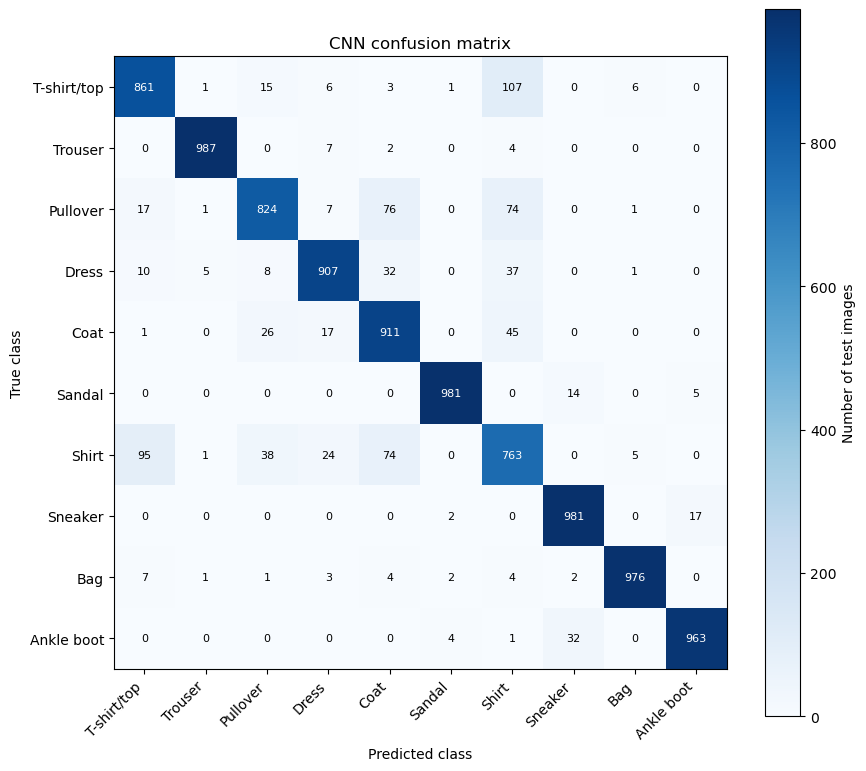

In [13]:
# Inspect CNN predictions by class
cnn_probabilities = cnn_model.predict(x_test_cnn, batch_size=256, verbose=0)
cnn_predictions = np.argmax(cnn_probabilities, axis=1)

confusion = tf.math.confusion_matrix(
    y_test,
    cnn_predictions,
    num_classes=len(class_names),
).numpy()

fig, ax = plt.subplots(figsize=(9, 8))
image = ax.imshow(confusion, cmap="Blues")
fig.colorbar(image, ax=ax, label="Number of test images")
ax.set_title("CNN confusion matrix")
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.set_xticks(range(len(class_names)), labels=class_names, rotation=45, ha="right")
ax.set_yticks(range(len(class_names)), labels=class_names)

threshold = confusion.max() / 2
for row in range(confusion.shape[0]):
    for column in range(confusion.shape[1]):
        ax.text(
            column, row, str(confusion[row, column]),
            ha="center", va="center",
            color="white" if confusion[row, column] > threshold else "black",
            fontsize=8,
        )

plt.tight_layout()
plt.show()


In [14]:
true_positives = np.diag(confusion)
precision_by_class = true_positives / np.maximum(confusion.sum(axis=0), 1)
recall_by_class = true_positives / np.maximum(confusion.sum(axis=1), 1)
f1_by_class = (
    2 * precision_by_class * recall_by_class
    / np.maximum(precision_by_class + recall_by_class, 1e-12)
)

print(f"{'Class':<14} {'Precision':>11} {'Recall':>10} {'F1':>10}")
print("-" * 48)
for index, class_name in enumerate(class_names):
    print(
        f"{class_name:<14} {precision_by_class[index]:>10.2%} "
        f"{recall_by_class[index]:>9.2%} {f1_by_class[index]:>9.2%}"
    )

print()
print(f"Macro-average F1: {f1_by_class.mean():.2%}")


Class            Precision     Recall         F1
------------------------------------------------
T-shirt/top        86.88%    86.10%    86.49%
Trouser            99.10%    98.70%    98.90%
Pullover           90.35%    82.40%    86.19%
Dress              93.41%    90.70%    92.03%
Coat               82.67%    91.10%    86.68%
Sandal             99.09%    98.10%    98.59%
Shirt              73.72%    76.30%    74.99%
Sneaker            95.34%    98.10%    96.70%
Bag                98.69%    97.60%    98.14%
Ankle boot         97.77%    96.30%    97.03%

Macro-average F1: 91.57%


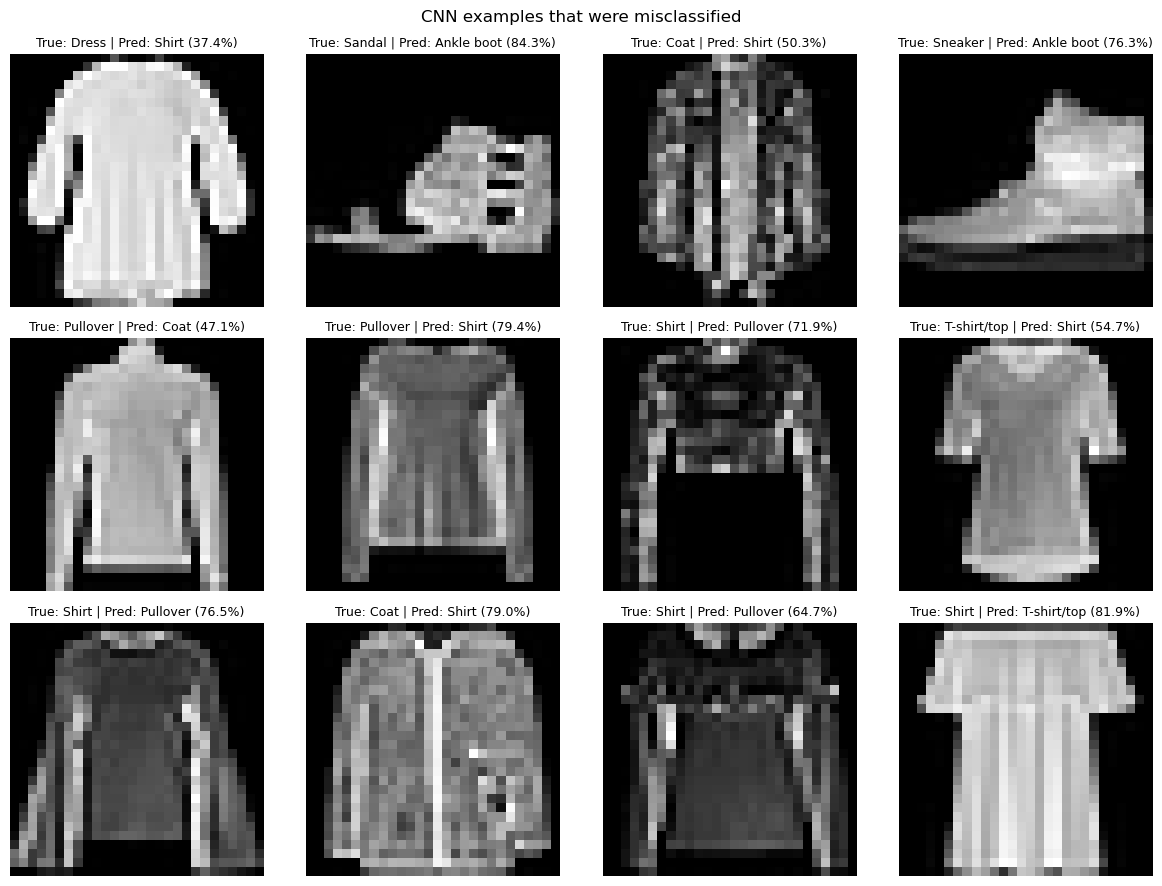

Misclassified test images: 846 / 10000


In [15]:
# View example mistakes
wrong_indices = np.flatnonzero(cnn_predictions != y_test)
number_to_show = min(12, len(wrong_indices))

if number_to_show == 0:
    print("The CNN made no mistakes on this test set.")
else:
    mistake_rng = np.random.default_rng(SEED)
    selected_indices = mistake_rng.choice(wrong_indices, size=number_to_show, replace=False)

    columns = 4
    rows = int(np.ceil(number_to_show / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(12, 3 * rows))
    axes = np.atleast_1d(axes).ravel()

    for ax, index in zip(axes, selected_indices):
        predicted_label = int(cnn_predictions[index])
        confidence = float(cnn_probabilities[index, predicted_label])
        ax.imshow(x_test_raw[index], cmap="gray")
        ax.set_title(
            f"True: {class_names[int(y_test[index])]} | Pred: {class_names[predicted_label]} ({confidence:.1%})",
            fontsize=9,
        )
        ax.axis("off")

    for ax in axes[number_to_show:]:
        ax.axis("off")

    fig.suptitle("CNN examples that were misclassified")
    plt.tight_layout()
    plt.show()

print(f"Misclassified test images: {len(wrong_indices)} / {len(y_test)}")


True label: Ankle boot
Predicted label: Ankle boot
Predicted-class probability: 99.99%


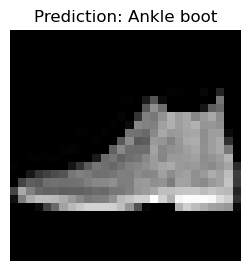

In [16]:
# Try one prediction
sample_index = 0
sample_image = x_test_cnn[sample_index]
sample_probabilities = cnn_model.predict(sample_image[np.newaxis, ...], verbose=0)[0]
predicted_class = int(np.argmax(sample_probabilities))

print("True label:", class_names[int(y_test[sample_index])])
print("Predicted label:", class_names[predicted_class])
print(f"Predicted-class probability: {sample_probabilities[predicted_class]:.2%}")

plt.figure(figsize=(3, 3))
plt.imshow(x_test_raw[sample_index], cmap="gray")
plt.title(f"Prediction: {class_names[predicted_class]}")
plt.axis("off")
plt.show()


In [17]:
# save the cnn model 
model_path = "fashion_mnist_cnn.keras"
cnn_model.save(model_path)
print(f"Saved model to: {model_path}")


Saved model to: fashion_mnist_cnn.keras
